# Missing values EDA: a reference version
**Goal:** understand *what is missing, why, and whether the gaps carry information*, so that handling it later (in a pipeline) is a justified decision, not a guess.

**How this differs from a quick pass**
1. **Train split only.** The data is split first (stratified, using `train_test_stratified` from the project) and every decision below uses the training rows. The test set is not touched. Numbers will differ slightly from a full-data analysis.
2. **Hidden missing values come before counting.** Placeholders (`XNA`, `365243`) are found and converted on a *copy* so the counts reflect what is really missing.
3. **Blocks are found automatically.** Columns missing on exactly the same rows are grouped by a signature, so you reason about a few blocks, not 120 columns.
4. **Every block gets the same tests:** target-rate gap with a standard error, what predicts the gap being missing, and whether the gap survives within subgroups.
5. **Nothing is imputed, dropped or changed in the data.** The output is a spec for the pipeline.

**The questions, in order**
1. What is missing, and how much? 2. Is anything missing but disguised? 3. Which columns go missing together? 4. Does missingness predict the target? 5. Why is it missing (structural, explained by other columns, or unexplained)? 6. Is the signal real or an artefact of who the applicants are?

## 0. Setup

In [ ]:
# --- setup
import os

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

from loan_default.config import ID_COL, RANDOM_SEED, TARGET
from loan_default.data.load import load_raw, train_test_stratified

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)

BLUE, GRAY, RED = "#2a78d6", "#52514e", "#e34948"   # one hue for magnitude, gray for ink
plt.rcParams.update(
    {
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
        "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
        "axes.edgecolor": "#c3c2b7", "xtick.color": GRAY, "ytick.color": GRAY, "text.color": "#0b0b0b",
    }
)


In [ ]:
# --- load and split
raw = load_raw()
train, test = train_test_stratified(raw)        # test is NOT used anywhere below
df = train.reset_index(drop=True).copy()    # .copy() also defragments the frame

print(f"raw: {raw.shape}   train (used here): {df.shape}   test (untouched): {test.shape}")
print(f"default rate  raw {raw[TARGET].mean():.4%}   train {df[TARGET].mean():.4%}   test {test[TARGET].mean():.4%}")


raw: (307511, 122)   train (used here): (246008, 122)   test (untouched): (61503, 122)
default rate  raw 8.0729%   train 8.0729%   test 8.0728%


## 1. What is missing, and how much?
`isna()` only finds `NaN`. This section measures the obvious gaps; section 2 looks for the disguised ones.

In [ ]:
# --- measure
def missing_table(frame):
    return pd.DataFrame(
        {"n_missing": frame.isna().sum(), "pct_missing": frame.isna().mean().mul(100)}
    ).sort_values("n_missing", ascending=False)


missing = missing_table(df)
bins = [-1, 0, 5, 10, 20, 30, 50, 100]
labels = ["0%", "0-5%", "5-10%", "10-20%", "20-30%", "30-50%", ">50%"]
buckets = pd.cut(missing["pct_missing"], bins=bins, labels=labels).value_counts().sort_index()
assert buckets.sum() == df.shape[1]

print(f"{(missing.n_missing > 0).sum()} of {df.shape[1]} columns contain NaN")
buckets.rename("n_columns").to_frame()


67 of 122 columns contain NaN


,n_columns
pct_missing,
0%,55
0-5%,10
5-10%,0
10-20%,7
20-30%,0
30-50%,9
>50%,41


**Reading the numbers.** 67 of 122 columns contain `NaN`; 55 are complete. 41 columns are more than 50% missing. The 5-10% and 20-30% buckets are genuinely empty (the bucket counts add up to 122), so missingness is bimodal: either a column is nearly complete, or it is missing for a large share of applicants. That pattern suggests a few *sources* of data that are absent for many applicants, rather than random noise spread across columns.

## 2. Is anything missing but disguised?
Placeholders look like data, so `isna()` cannot see them. Text columns are scanned for placeholder labels; numeric columns for one value that takes an unusual share of a column, impossible signs and extreme maxima.

In [ ]:
# --- text placeholders
PLACEHOLDERS = {"xna", "unknown", "n/a", "na", "?", "", "none", "null", "nan"}


def is_placeholder(s):
    """True where a text value is a placeholder. Real NaN is never counted as one."""
    cleaned = s.astype("string").str.strip().str.lower()
    return cleaned.isin(PLACEHOLDERS).fillna(False).astype(bool)


text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
hits = {c: is_placeholder(df[c]) for c in text_cols}
rows = [
    {"column": c, "n_placeholder": int(m.sum()), "labels": sorted(df.loc[m, c].unique().tolist())}
    for c, m in hits.items()
    if m.any()
]
pd.DataFrame(rows)


,column,n_placeholder,labels
0,CODE_GENDER,2,[XNA]
1,NAME_FAMILY_STATUS,2,[Unknown]
2,ORGANIZATION_TYPE,44143,[XNA]


In [ ]:
# --- numeric placeholders
int_cols = df.select_dtypes(include="int").columns
binary_flags = [c for c in int_cols if df[c].nunique(dropna=True) == 2]
numeric_cols = [
    c for c in df.select_dtypes(include="number").columns if c not in binary_flags and c not in (ID_COL, TARGET)
]

rows = []
for c in numeric_cols:
    vc = df[c].dropna().value_counts(normalize=True)
    rows.append(
        {
            "col": c,
            "top_value": vc.index[0],
            "top_share_%": 100 * vc.iloc[0],
            "second_share_%": 100 * vc.iloc[1] if len(vc) > 1 else 0.0,
        }
    )
scan = pd.DataFrame(rows)
spike = scan[(scan["top_share_%"] >= 5) & (scan["top_share_%"] >= 3 * scan["second_share_%"])]
print(f"{len(spike)} numeric columns have a dominant value; {(spike.top_value == 0).sum()} are zero-heavy counts (usually genuine)")
print("\nDominant value that is NOT zero (candidates):")
display(spike[spike.top_value != 0].round(2))

days_cols = [c for c in df.columns if c.startswith("DAYS_")]
print("DAYS_* columns with positive values (they should be <= 0):", {c: int((df[c] > 0).sum()) for c in days_cols if (df[c] > 0).any()})


32 numeric columns have a dominant value; 29 are zero-heavy counts (usually genuine)

Dominant value that is NOT zero (candidates):


,col,top_value,top_share_%,second_share_%
7,DAYS_EMPLOYED,365243.0,17.94,0.05
12,REGION_RATING_CLIENT,2.0,73.83,15.70
13,REGION_RATING_CLIENT_W_CITY,2.0,74.64,14.25


DAYS_* columns with positive values (they should be <= 0): {'DAYS_EMPLOYED': 44143}


In [ ]:
# --- extreme maxima (outliers, a different problem)
ext = pd.DataFrame({"q99": df[numeric_cols].quantile(0.99), "max": df[numeric_cols].max()})
ext["max_vs_q99"] = ext["max"] / ext["q99"].where(ext["q99"] > 0)
print("Maxima far above the 99th percentile: outliers, not missing values. Parked for an outlier step.")
ext[ext.max_vs_q99 > 10].sort_values("max_vs_q99", ascending=False).round(1)


Maxima far above the 99th percentile: outliers, not missing values. Parked for an outlier step.


,q99,max,max_vs_q99
AMT_INCOME_TOTAL,472500.0,117000000.0,247.6
OBS_30_CNT_SOCIAL_CIRCLE,10.0,348.0,34.8
OBS_60_CNT_SOCIAL_CIRCLE,10.0,344.0,34.4
DEF_30_CNT_SOCIAL_CIRCLE,2.0,34.0,17.0
DEF_60_CNT_SOCIAL_CIRCLE,2.0,24.0,12.0
NONLIVINGAPARTMENTS_MODE,0.1,1.0,10.3


In [ ]:
# --- confirm and convert (on a COPY)
# Rules come from the scans above. Each was checked against the data dictionary.
PLACEHOLDER_RULES = {
    "DAYS_EMPLOYED": [365243],           # ~1000 years; 18% of rows
    "ORGANIZATION_TYPE": ["XNA"],
    "CODE_GENDER": ["XNA"],
    "NAME_FAMILY_STATUS": ["Unknown"],
}


def placeholders_to_nan(frame, rules=PLACEHOLDER_RULES):
    out = frame.copy()
    for col, values in rules.items():
        out[col] = out[col].mask(out[col].isin(values))
    return out


dfn = placeholders_to_nan(df)     # df stays raw. dfn is "effective missingness".
effective = pd.DataFrame(
    {
        "n_missing_raw": df[list(PLACEHOLDER_RULES)].isna().sum(),
        "n_missing_effective": dfn[list(PLACEHOLDER_RULES)].isna().sum(),
    }
)
effective["pct_effective"] = (effective.n_missing_effective / len(df) * 100).round(2)
effective


,n_missing_raw,n_missing_effective,pct_effective
DAYS_EMPLOYED,0,44143,17.94
ORGANIZATION_TYPE,0,44143,17.94
CODE_GENDER,0,2,0.00
NAME_FAMILY_STATUS,0,2,0.00


**What the scans found (training split, 246,008 rows)**
- `ORGANIZATION_TYPE == "XNA"` on **44,143 rows (17.9%)** and `DAYS_EMPLOYED == 365243` (about 1,000 years) on the same count. These are placeholders, not data. Section 5 shows they mark the same applicants.
- `CODE_GENDER == "XNA"` (2 rows) and `NAME_FAMILY_STATUS == "Unknown"` (2 rows): placeholders in negligible groups.
- The other dominant numeric values are genuine: zero-heavy counts (bureau inquiries, social-circle counts, children) and `REGION_RATING_*` where 2 is simply the most common category.
- Extreme maxima (`AMT_INCOME_TOTAL` reaches 117 million, a few count columns far above their 99th percentile) are **outliers, not missing values**. They are parked for an outlier step.

**Limits of the scan.** It finds a placeholder only when it dominates a column (at least 5% and at least 3 times the next value) or sits in a text column. A numeric placeholder on a few rows would not be caught. `DAYS_LAST_PHONE_CHANGE == 0` (about 12% of rows) is in the zero-heavy group and was left alone because a phone changed on the application day is plausible, but it is **unresolved**: check the data dictionary before relying on it.

`dfn` is a converted *copy*. The raw `df` is untouched, and `dfn` is used from here on so that counts reflect real missingness.

## 3. Which columns go missing together?
Two columns are in the same **block** if they are missing on *exactly* the same rows. The signature of a column is a hash of its True/False missing mask, and equal signatures mean identical masks. This is exact, unlike a heatmap, which only shows correlation (and rounds 99.9% up to 100%).

In [ ]:
# --- blocks
mask = dfn.drop(columns=[ID_COL, TARGET]).isna()
mask = mask.loc[:, mask.any()]                 # keep only columns that have at least one gap
HOUSING_TOKENS = ("_AVG", "_MEDI", "_MODE")


def semantic_group(c):
    if any(t in c for t in HOUSING_TOKENS):
        return "Housing"
    if c.startswith("EXT_SOURCE"):
        return "Ext source"
    if c.startswith("AMT_REQ_CREDIT_BUREAU"):
        return "Credit bureau"
    if "_CNT_SOCIAL_CIRCLE" in c:
        return "Social circle"
    if c in ("DAYS_EMPLOYED", "ORGANIZATION_TYPE"):
        return "Employment placeholder"
    if c == "OCCUPATION_TYPE":
        return "Occupation"
    if c == "OWN_CAR_AGE":
        return "Car"
    return "Other"


def stem(c):
    return c.rsplit("_", 1)[0] if c.endswith(HOUSING_TOKENS) else c


def block_label(members):
    stems = list(dict.fromkeys(stem(m) for m in members))
    if len(stems) == 1:
        return stems[0]
    prefix = os.path.commonprefix(stems).rstrip("_")
    suffix = os.path.commonprefix([s[::-1] for s in stems])[::-1].lstrip("_0123456789")
    if len(prefix) >= 6:
        return prefix + "_*"
    if len(suffix) >= 6:
        return "*_" + suffix
    return ", ".join(stems[:2]) + (f" +{len(stems) - 2}" if len(stems) > 2 else "")


signature = mask.apply(lambda s: hash(s.to_numpy().tobytes()))
rows = []
for _, sub in signature.groupby(signature):
    members = list(sub.index)
    rows.append(
        {
            "block": block_label(members),
            "rep": members[0],
            "n_cols": len(members),
            "pct_missing": mask[members[0]].mean() * 100,
            "group": semantic_group(members[0]),
            "columns": members,
        }
    )
blocks = pd.DataFrame(rows).sort_values("pct_missing", ascending=False).reset_index(drop=True)
assert blocks.n_cols.sum() == mask.shape[1]

print(f"{mask.shape[1]} columns with gaps collapse into {len(blocks)} blocks (identical missing rows)")
display(blocks.groupby("group").agg(n_blocks=("block", "size"), n_columns=("n_cols", "sum")))
blocks[["block", "n_cols", "pct_missing", "group"]].round(1)


71 columns with gaps collapse into 33 blocks (identical missing rows)


,n_blocks,n_columns
group,,
Car,1,1
Credit bureau,1,6
Employment placeholder,1,2
Ext source,3,3
Housing,19,47
Occupation,1,1
Other,6,7
Social circle,1,4


,block,n_cols,pct_missing,group
0,COMMONAREA,3,69.8,Housing
1,NONLIVINGAPARTMENTS,3,69.4,Housing
2,FONDKAPREMONT,1,68.4,Housing
3,LIVINGAPARTMENTS,3,68.3,Housing
4,FLOORSMIN,3,67.9,Housing
5,YEARS_BUILD,3,66.5,Housing
6,OWN_CAR_AGE,1,66.0,Car
7,LANDAREA,3,59.3,Housing
8,BASEMENTAREA,3,58.5,Housing
9,EXT_SOURCE_1,1,56.3,Ext source


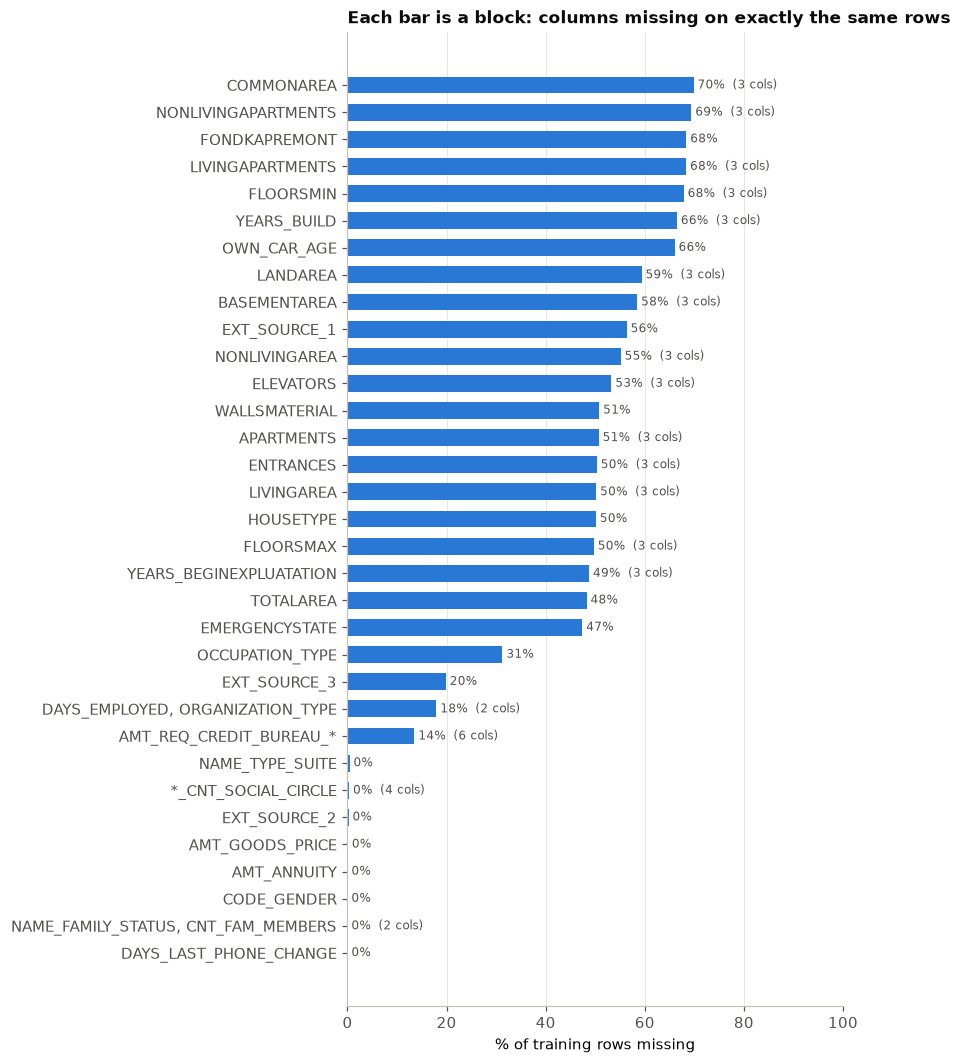

In [ ]:
# --- blocks chart
plot = blocks.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 0.26 * len(plot) + 1.2))
ax.barh(plot.block, plot.pct_missing, color=BLUE, height=0.62)
for y, (v, n) in enumerate(zip(plot.pct_missing, plot.n_cols)):
    ax.text(v + 0.8, y, f"{v:.0f}%" + (f"  ({n} cols)" if n > 1 else ""), va="center", fontsize=8, color=GRAY)
ax.set_xlim(0, 100)
ax.set_xlabel("% of training rows missing")
ax.set_title("Each bar is a block: columns missing on exactly the same rows")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()


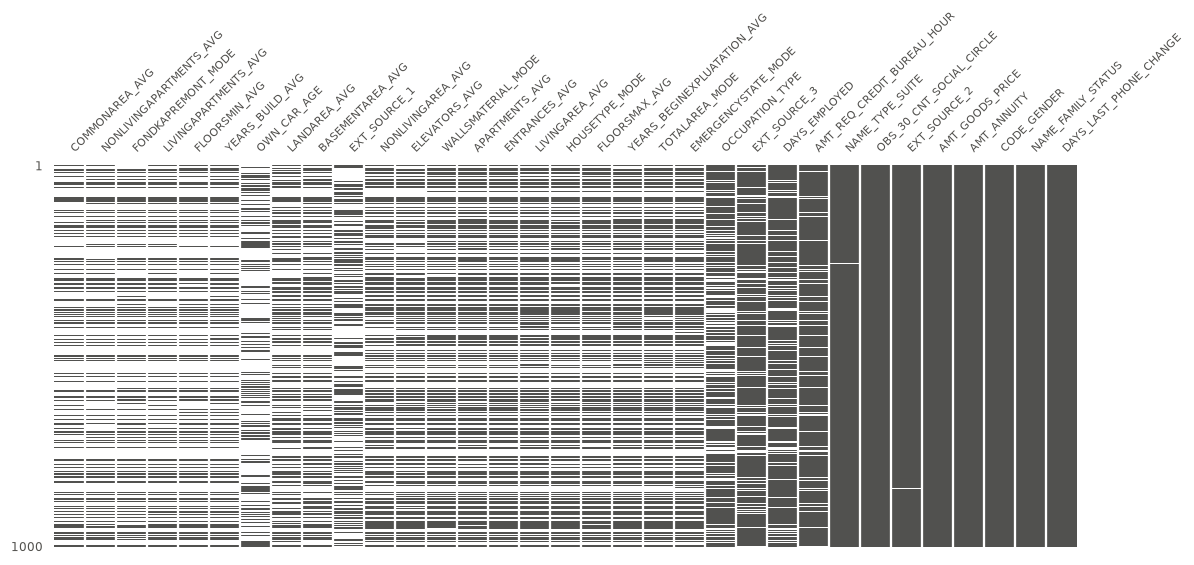

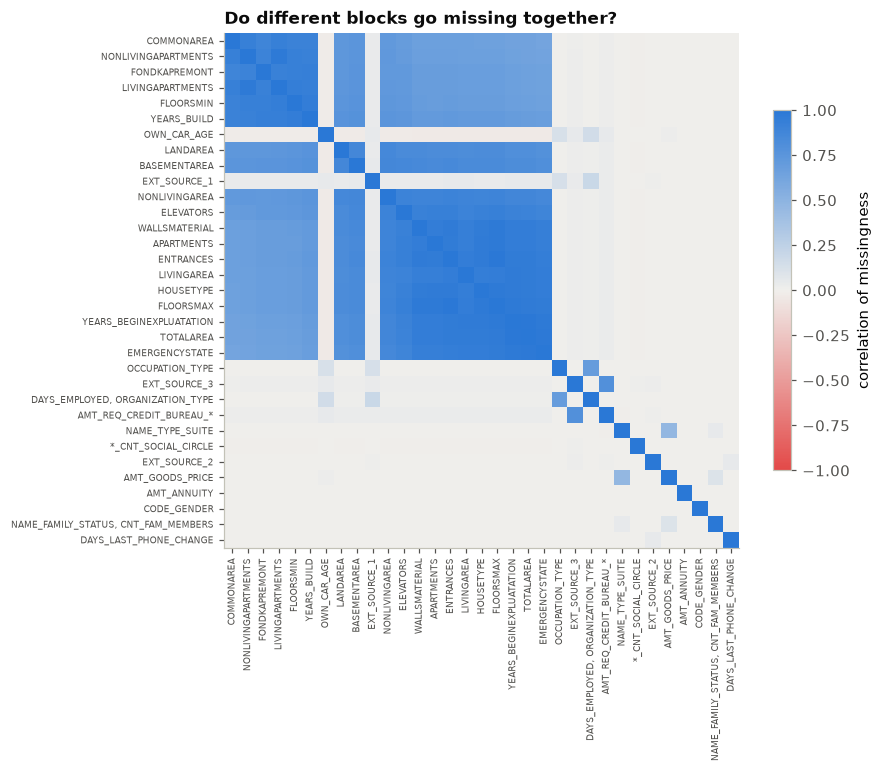

In [ ]:
# --- matrix and block correlation
reps = blocks.rep.tolist()
msno.matrix(dfn[reps].sample(1000, random_state=RANDOM_SEED), figsize=(12, 4.5), fontsize=7, sparkline=False, color=(0.32, 0.32, 0.31))
plt.show()

from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("div", [RED, "#f0efec", BLUE])
corr = mask[reps].astype(float).corr()
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(reps)), blocks.block, rotation=90, fontsize=6)
ax.set_yticks(range(len(reps)), blocks.block, fontsize=6)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="correlation of missingness")
ax.set_title("Do different blocks go missing together?")
plt.tight_layout()
plt.show()


In [ ]:
# --- cross-group correlations
grp = dict(zip(blocks.rep, blocks.group))
label = dict(zip(blocks.rep, blocks.block))
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("corr").reset_index()
pairs.columns = ["rep_a", "rep_b", "corr"]
pairs["group_a"], pairs["group_b"] = pairs.rep_a.map(grp), pairs.rep_b.map(grp)
pairs["block_a"], pairs["block_b"] = pairs.rep_a.map(label), pairs.rep_b.map(label)
cross = pairs[(pairs.group_a != pairs.group_b) & (pairs["corr"] > 0.3)].sort_values("corr", ascending=False)
print("Blocks from DIFFERENT groups whose missingness is correlated (> 0.3):")
cross[["block_a", "block_b", "corr"]].round(2)


Blocks from DIFFERENT groups whose missingness is correlated (> 0.3):


,block_a,block_b,corr
750,EXT_SOURCE_3,AMT_REQ_CREDIT_BUREAU_*,0.79
716,OCCUPATION_TYPE,"DAYS_EMPLOYED, ORGANIZATION_TYPE",0.69


**What the structure looks like**
- 71 columns with gaps collapse into **33 blocks** of identical missing rows.
- **Housing:** 47 columns become 19 blocks. Each `_AVG`/`_MODE`/`_MEDI` triple is missing on identical rows, and a few single columns (`FONDKAPREMONT`, `HOUSETYPE`, `WALLSMATERIAL`, `EMERGENCYSTATE`, `TOTALAREA`) form their own blocks. The 19 blocks are strongly but not perfectly correlated with each other.
- **Credit bureau:** 6 columns, 1 block. **Social circle:** 4 columns, 1 block.
- **`EXT_SOURCE_1/2/3`:** three separate blocks, so their gaps are independent of each other.
- Two links *across* groups: `EXT_SOURCE_3` with the bureau block (**0.79**) and `OCCUPATION_TYPE` with the employment placeholder (**0.69**). The second is explained in section 5 (pensioners). The first is a hypothesis: `EXT_SOURCE_3` may be derived from bureau data, so it is missing for many of the same applicants. Treat it as redundancy to keep in mind when adding flags.

**Housing is not a single on/off block.** The 47 housing columns collapse into a smaller set of blocks with different missing rates, so a row can have some of them and not others. The next cell summarises each row by the *state of the whole housing set*.

In [ ]:
# --- housing state
housing_cols = [c for c in dfn.columns if semantic_group(c) == "Housing"]
n_missing_housing = dfn[housing_cols].isna().sum(axis=1)
housing_state = pd.Series(
    np.select(
        [n_missing_housing == 0, n_missing_housing == len(housing_cols)],
        ["none missing", "all missing"],
        default="partial",
    ),
    index=dfn.index,
    name="housing_state",
)
print(f"{len(housing_cols)} housing columns")
display(
    df.groupby(housing_state)[TARGET].agg(n_rows="count", default_rate="mean")
    .assign(default_rate=lambda x: x["default_rate"].mul(100).round(2))
    .loc[["none missing", "partial", "all missing"]]
)

# how many distinct blocks are missing on a row, across the whole dataset
(mask[reps].sum(axis=1).value_counts().sort_index().rename("n_rows").to_frame().rename_axis("blocks_missing_on_row"))


47 housing columns


,n_rows,default_rate
housing_state,,
none missing,62923,7.00
partial,66504,7.02
all missing,116581,9.25


,n_rows
blocks_missing_on_row,
0,6815
1,20204
2,19951
3,12920
4,11836
5,4785
6,4892
7,6911
8,8065


**The signal sits in "all housing missing".** Rows with all housing data missing default at **9.25%**; rows with none missing at **7.00%**; rows with *some* missing at **7.02%**, i.e. indistinguishable from none. One binary "all housing missing" flag captures it. This also explains why testing a single column such as `COMMONAREA` (70% missing) understates the effect: it mixes partial rows (which behave normally) with all-missing rows.

## 4. Does missingness predict the target?
For each block, compare the default rate of rows where it is missing with the rest, with a standard error. `z = gap / se`. A large `z` says the gap is **real**, not that it is **large**: read `gap_pts` and `n_flag` too. About 35 tests are run, so very small `z` values (2 to 3) should not be over-read.

In [ ]:
# --- compare_flag
def compare_flag(flag, target, name=""):
    """Rate gap between flagged rows and the rest.

    z uses the POOLED standard error (the standard two-proportion test), which stays sensible for tiny
    groups. An unpooled error collapses to 0 when a tiny group has 0 defaults and gives an absurd z.
    se_pts (used for the plotted interval) uses the Agresti-Coull adjustment for the same reason.
    """
    flag = flag.fillna(False).astype(bool)
    n_flag, n_other = int(flag.sum()), int((~flag).sum())
    x_flag, x_other = target[flag].sum(), target[~flag].sum()
    p_flag, p_other = x_flag / n_flag, x_other / n_other
    p_pool = (x_flag + x_other) / (n_flag + n_other)
    z = (p_flag - p_other) / np.sqrt(p_pool * (1 - p_pool) * (1 / n_flag + 1 / n_other))
    a_flag, a_other = (x_flag + 2) / (n_flag + 4), (x_other + 2) / (n_other + 4)
    se = np.sqrt(a_flag * (1 - a_flag) / n_flag + a_other * (1 - a_other) / n_other)
    return {
        "flag": name, "n_flag": n_flag, "n_other": n_other,
        "rate_flag_%": 100 * p_flag, "rate_other_%": 100 * p_other,
        "gap_pts": 100 * (p_flag - p_other), "se_pts": 100 * se, "z": z,
    }


# housing is 19 near-identical tests, so it enters as ONE aggregate row. Its blocks are summarised below.
flags = {row.block: mask[row.rep] for row in blocks.itertuples() if row.group != "Housing"}
flags["HOUSING: all missing"] = housing_state == "all missing"

housing_gaps = pd.DataFrame(
    [compare_flag(mask[r.rep], df[TARGET], r.block) for r in blocks.itertuples() if r.group == "Housing"]
)
print(f"the {len(housing_gaps)} individual housing blocks: gap {housing_gaps.gap_pts.min():.2f} to {housing_gaps.gap_pts.max():.2f} pts, z {housing_gaps.z.min():.1f} to {housing_gaps.z.max():.1f}")

effects = pd.DataFrame([compare_flag(f, df[TARGET], name) for name, f in flags.items()])
effects = effects.sort_values("z", key=abs, ascending=False).reset_index(drop=True)
effects.round(2)


the 19 individual housing blocks: gap 1.60 to 2.24 pts, z 13.4 to 20.4


,flag,n_flag,n_other,rate_flag_%,rate_other_%,gap_pts,se_pts,z
0,"DAYS_EMPLOYED, ORGANIZATION_TYPE",44143,201865,5.37,8.66,-3.30,0.12,-23.02
1,HOUSING: all missing,116581,129427,9.25,7.01,2.24,0.11,20.37
2,OCCUPATION_TYPE,76940,169068,6.49,8.79,-2.30,0.11,-19.42
3,AMT_REQ_CREDIT_BUREAU_*,33244,212764,10.34,7.72,2.62,0.18,16.31
4,EXT_SOURCE_3,48805,197203,9.28,7.77,1.50,0.14,10.91
5,OWN_CAR_AGE,162418,83590,8.48,7.27,1.21,0.11,10.42
6,EXT_SOURCE_1,138595,107413,8.52,7.49,1.04,0.11,9.35
7,*_CNT_SOCIAL_CIRCLE,811,245197,3.95,8.09,-4.14,0.70,-4.32
8,NAME_TYPE_SUITE,1029,244979,5.54,8.08,-2.54,0.73,-2.99
9,AMT_ANNUITY,10,245998,0.00,8.07,-8.07,11.07,-0.94


4 blocks with fewer than 100 flagged rows are left off the chart (too small to show)


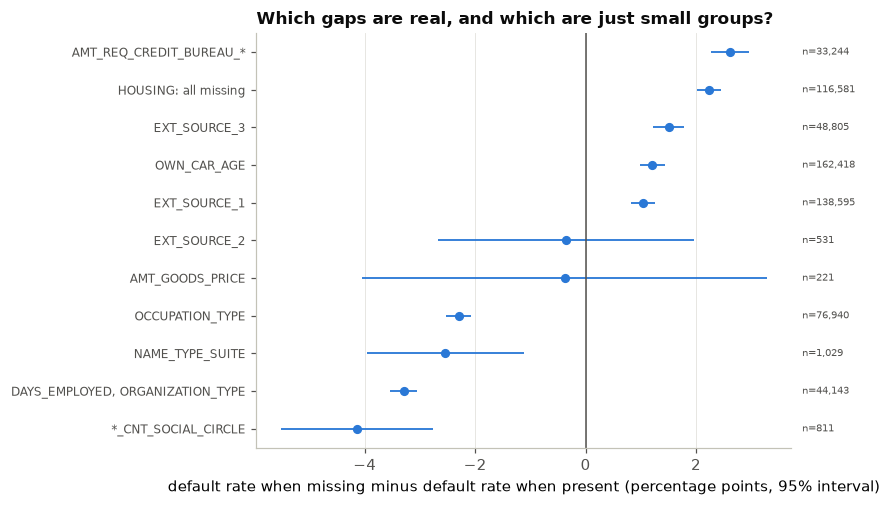

In [ ]:
# --- forest chart
plot = effects[effects.n_flag >= 100].sort_values("gap_pts").reset_index(drop=True)
print(f"{(effects.n_flag < 100).sum()} blocks with fewer than 100 flagged rows are left off the chart (too small to show)")
fig, ax = plt.subplots(figsize=(8, 0.3 * len(plot) + 1.4))
ax.errorbar(plot.gap_pts, range(len(plot)), xerr=1.96 * plot.se_pts, fmt="o", color=BLUE, ecolor=BLUE, elinewidth=1.2, ms=5, capsize=0)
ax.axvline(0, color=GRAY, lw=1)
ax.set_yticks(range(len(plot)), plot.flag, fontsize=8)
for y, n in enumerate(plot.n_flag):
    ax.text(1.02, y, f"n={n:,}", transform=ax.get_yaxis_transform(), va="center", fontsize=6.5, color=GRAY)
ax.set_xlabel("default rate when missing minus default rate when present (percentage points, 95% interval)")
ax.set_title("Which gaps are real, and which are just small groups?")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()


**Reading the gaps** (default rate when missing minus when present; *z* uses a pooled standard error so tiny groups behave; about 15 tests are run, so treat *z* of 2-3 with care)

| Block | n flagged | Missing | Present | Gap (pts) | z |
|---|---|---|---|---|---|
| Employment placeholder (`DAYS_EMPLOYED`, `ORGANIZATION_TYPE`) | 44,143 | 5.37% | 8.66% | -3.30 | -23.0 |
| Housing: all missing | 116,581 | 9.25% | 7.01% | +2.24 | 20.4 |
| `OCCUPATION_TYPE` | 76,940 | 6.49% | 8.79% | -2.30 | -19.4 |
| Credit bureau (6 cols) | 33,244 | 10.34% | 7.72% | +2.62 | 16.3 |
| `EXT_SOURCE_3` | 48,805 | 9.28% | 7.77% | +1.50 | 10.9 |
| `OWN_CAR_AGE` | 162,418 | 8.48% | 7.27% | +1.21 | 10.4 |
| `EXT_SOURCE_1` | 138,595 | 8.52% | 7.49% | +1.04 | 9.4 |

- Social circle (811 rows, 3.95% vs 8.09%, *z* -4.3) is real but covers 0.3% of applicants, so it matters little. `NAME_TYPE_SUITE` (1,029 rows) is borderline (*z* -3.0). `EXT_SOURCE_2`, `AMT_GOODS_PRICE` and the tiny groups cannot be told apart from zero.
- A large *z* only says a gap is **real**. Compare `gap_pts` and `n_flag` for how much it could matter. Neither says missingness *causes* anything.

## 5. Why is it missing?
Three possibilities: **structural** (the value does not exist for that applicant), **explained by other columns** (missing at random given what we can see), or **unexplained**. Two tools: a direct check of the obvious structural links, and a model that tries to predict "is this block missing?" from columns that are never missing. If that model scores near AUC 0.5, the gaps look unrelated to the observed columns. Near 1.0, they are determined by them.

In [ ]:
# --- structural links
# Car: OWN_CAR_AGE vs FLAG_OWN_CAR
age_missing = df["OWN_CAR_AGE"].isna().rename("age_missing")
no_car = (df["FLAG_OWN_CAR"] == "N").rename("no_car")
display(pd.crosstab(age_missing, no_car, margins=True))
print("car owners with no age:", int((age_missing & ~no_car).sum()), " non-owners with an age:", int((~age_missing & no_car).sum()))

# Employment placeholder vs pensioners
is_pens = (df["NAME_INCOME_TYPE"] == "Pensioner").rename("pensioner")
is_emp_ph = dfn["DAYS_EMPLOYED"].isna().rename("employment_placeholder")
display(pd.crosstab(is_pens, is_emp_ph, margins=True))
print(f"share of placeholder rows that are pensioners: {is_pens[is_emp_ph].mean():.2%}   share of pensioners that are placeholders: {is_emp_ph[is_pens].mean():.2%}")
print("same rows as ORGANIZATION_TYPE=XNA:", bool((dfn["DAYS_EMPLOYED"].isna() == dfn["ORGANIZATION_TYPE"].isna()).all()))


no_car,False,True,All
age_missing,,,
False,83590,0,83590
True,5,162413,162418
All,83595,162413,246008


car owners with no age: 5  non-owners with an age: 0


employment_placeholder,False,True,All
pensioner,,,
False,201857,17,201874
True,8,44126,44134
All,201865,44143,246008


share of placeholder rows that are pensioners: 99.96%   share of pensioners that are placeholders: 99.98%
same rows as ORGANIZATION_TYPE=XNA: True


In [ ]:
# --- occupation
occ_missing = df["OCCUPATION_TYPE"].isna()
by_income = (
    occ_missing.groupby(df["NAME_INCOME_TYPE"]).agg(n_missing="sum", n_rows="count", share_missing="mean")
    .sort_values("n_rows", ascending=False)
)
by_income["share_missing"] = by_income["share_missing"].mul(100).round(1)
display(by_income)
print(f"pensioners account for {(occ_missing & is_pens).sum():,} of {occ_missing.sum():,} missing occupations")
pd.DataFrame([compare_flag(occ_missing[~is_pens], df.loc[~is_pens, TARGET], "occupation missing, non-pensioners only")]).round(2)


,n_missing,n_rows,share_missing
NAME_INCOME_TYPE,,,
Working,19922,127043,15.7
Commercial associate,9869,57273,17.2
Pensioner,44130,44134,100.0
State servant,2997,17518,17.1
Unemployed,17,17,100.0
Student,2,11,18.2
Businessman,2,9,22.2
Maternity leave,1,3,33.3


pensioners account for 44,130 of 76,940 missing occupations


,flag,n_flag,n_other,rate_flag_%,rate_other_%,gap_pts,se_pts,z
0,"occupation missing, non-pensioners only",32810,169064,8.02,8.79,-0.78,0.17,-4.58


**Structural links, confirmed on the training split**
- **Car:** all 162,413 applicants with no car have no `OWN_CAR_AGE`; 0 non-owners have an age; 5 owners are missing it. So `OWN_CAR_AGE` missingness *is* "no car". It is structural and not a data gap.
- **Employment placeholder:** 99.96% of placeholder rows are pensioners, and 99.98% of pensioners have the placeholder (17 non-pensioners and 8 pensioners are the exceptions). It is the same rows as `ORGANIZATION_TYPE == "XNA"`. "XNA" and `365243` both mean "not applicable: no employer".
- **`OCCUPATION_TYPE`:** 44,130 of its 76,940 missing values are pensioners (structural). For the other 32,810, the missing share is a steady 16-17% in every income type, which looks like ordinary gaps. Among non-pensioners only, missing occupation still defaults less (8.02% vs 8.79%, *z* -4.6), but the gap is **-0.78 points, not the headline -2.30**: most of the headline is the pensioner effect.

In [ ]:
# --- predict the flag
complete_cols = [c for c in dfn.columns if c not in (ID_COL, TARGET) and not dfn[c].isna().any()]
X_all = dfn[complete_cols].copy()
for c in X_all.columns:
    if not pd.api.types.is_numeric_dtype(X_all[c]):
        X_all[c] = X_all[c].astype("category")

sample_idx = X_all.sample(80_000, random_state=RANDOM_SEED).index
key = effects[(effects.n_flag >= 1000) & (effects.z.abs() >= 3)]
rows = []
for name in key.flag:
    y = flags[name].loc[sample_idx].astype(int)
    Xtr, Xva, ytr, yva = train_test_split(X_all.loc[sample_idx], y, test_size=0.3, stratify=y, random_state=RANDOM_SEED)
    model = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=RANDOM_SEED).fit(Xtr, ytr)
    rows.append({"flag": name, "auc_predicting_missingness": roc_auc_score(yva, model.predict_proba(Xva)[:, 1])})
print(f"predictors: {len(complete_cols)} columns that are never missing (the target is excluded)")
pd.DataFrame(rows).round(3)


predictors: 49 columns that are never missing (the target is excluded)


,flag,auc_predicting_missingness
0,"DAYS_EMPLOYED, ORGANIZATION_TYPE",1.000
1,HOUSING: all missing,0.773
2,OCCUPATION_TYPE,0.805
3,AMT_REQ_CREDIT_BUREAU_*,0.639
4,EXT_SOURCE_3,0.619
5,OWN_CAR_AGE,1.000
6,EXT_SOURCE_1,0.693


**Can the other columns predict where a block is missing?** (AUC of a gradient-boosted model using the 49 never-missing columns, 80k sample, held-out 30%)
- **1.00** for the employment placeholder and `OWN_CAR_AGE`: fully determined by other columns, i.e. structural.
- **0.81** `OCCUPATION_TYPE` and **0.77** housing all-missing: largely explained by observed columns, so the gaps are *not* random. This is consistent with missing at random given what we can see.
- **0.69** `EXT_SOURCE_1`, **0.64** bureau, **0.62** `EXT_SOURCE_3`: only weakly predictable. Most of why these are missing is *not* visible in the other columns, which fits a separate data source being unavailable for some applicants (and cannot be tested further from this data).

In [ ]:
# --- who has no housing data
hs = housing_state.rename("housing_state")
display(pd.crosstab(hs, df["NAME_HOUSING_TYPE"], normalize="index").mul(100).round(1))
df.assign(age_years=-df["DAYS_BIRTH"] / 365).groupby(hs).agg(
    median_income=("AMT_INCOME_TOTAL", "median"),
    median_age=("age_years", "median"),
    mean_region_pop=("REGION_POPULATION_RELATIVE", "mean"),
    share_cash_loans=("NAME_CONTRACT_TYPE", lambda s: (s == "Cash loans").mean()),
).round(3)


NAME_HOUSING_TYPE,Co-op apartment,House / apartment,Municipal apartment,Office apartment,Rented apartment,With parents
housing_state,,,,,,
all missing,0.3,88.8,2.3,0.9,2.1,5.5
none missing,0.4,89.0,4.5,0.8,1.0,4.3
partial,0.5,88.4,5.1,0.7,1.2,4.1


,median_income,median_age,mean_region_pop,share_cash_loans
housing_state,,,,
all missing,135000.0,42.912,0.019,0.913
none missing,157500.0,43.449,0.024,0.895
partial,157500.0,43.166,0.021,0.899


**Who has no housing data?** Applicants with all housing data missing have a lower median income (135,000 vs 157,500), live in less densely populated regions (mean relative population 0.019 vs 0.024), are more often in rented accommodation (2.1% vs 1.0%) and less often in municipal housing (2.3% vs 4.5%). That suggests housing data is missing more for lower-income applicants in less populated regions. It is plausible but not proof, and it means the missingness flag may partly stand in for those other characteristics.

## 6. Is the signal real, or just who the applicants are?
A gap between missing and present rows can be an artefact: if the missing rows contain more of a group that defaults more (or less) anyway, the gap says nothing about missingness itself. Check by repeating the comparison *within* subgroups (here, income type). A real signal survives.

In [ ]:
# --- within-stratum check
strata = df["NAME_INCOME_TYPE"].value_counts().loc[lambda s: s > 5000].index
bureau_rep = blocks.loc[blocks.group == "Credit bureau", "rep"].iloc[0]
checks = {
    "HOUSING: all missing": flags["HOUSING: all missing"],
    "credit bureau missing": mask[bureau_rep],
    "EXT_SOURCE_3 missing": mask["EXT_SOURCE_3"],
    "EXT_SOURCE_1 missing": mask["EXT_SOURCE_1"],
    "OWN_CAR_AGE missing": mask["OWN_CAR_AGE"],
}
rows = []
for name, f in checks.items():
    overall = compare_flag(f, df[TARGET], name)
    rows.append({**overall, "stratum": "ALL"})
    for inc in strata:
        m = df["NAME_INCOME_TYPE"] == inc
        if f[m].sum() > 200:
            rows.append({**compare_flag(f[m], df.loc[m, TARGET], name), "stratum": inc})
pd.DataFrame(rows)[["flag", "stratum", "n_flag", "n_other", "rate_flag_%", "rate_other_%", "gap_pts", "z"]].round(2)


,flag,stratum,n_flag,n_other,rate_flag_%,rate_other_%,gap_pts,z
0,HOUSING: all missing,ALL,116581,129427,9.25,7.01,2.24,20.37
1,HOUSING: all missing,Working,63203,63840,10.79,8.30,2.49,15.10
2,HOUSING: all missing,Commercial associate,23288,33985,8.93,6.68,2.25,9.99
3,HOUSING: all missing,Pensioner,21479,22655,6.02,4.73,1.29,6.01
4,HOUSING: all missing,State servant,8596,8922,6.89,4.84,2.04,5.77
5,credit bureau missing,ALL,33244,212764,10.34,7.72,2.62,16.31
6,credit bureau missing,Working,17465,109578,12.24,9.11,3.13,13.09
7,credit bureau missing,Commercial associate,7868,49405,9.34,7.31,2.03,6.31
8,credit bureau missing,Pensioner,6103,38031,6.91,5.11,1.81,5.81
9,credit bureau missing,State servant,1786,15732,7.67,5.64,2.03,3.47


**Do the gaps survive within income types?** (missing vs present, inside each type)
- **Housing all-missing:** +2.49 (Working), +2.25 (Commercial associate), +1.29 (Pensioner), +2.04 (State servant). It survives everywhere.
- **Credit bureau:** +3.13, +2.03, +1.81, +2.03. It survives everywhere.
- **`EXT_SOURCE_3`:** +1.91, +0.66, +1.19, +1.41. It survives, weaker for Commercial associates (*z* 2.4).
- **`OWN_CAR_AGE`:** +1.95, +1.62, +0.74, +1.18. It survives, weaker for pensioners.
- **`EXT_SOURCE_1`:** the overall +1.04 hides a mix effect. Within Working (+1.87), Commercial associate (+1.64) and State servant (+1.08) the gap is larger, but among **pensioners it is about zero** (+0.12, *z* 0.5). 33,884 of the 44,134 pensioners (77%) are missing `EXT_SOURCE_1`, and pensioners default less anyway, which dilutes the pooled gap.

So these signals are not simply an artefact of income type. They control for one variable only; other confounders are possible.

## 7. Output: a spec for the pipeline

In [ ]:
# --- spec
candidate_flags = effects.loc[(effects.n_flag >= 1000) & (effects.z.abs() >= 3), ["flag", "gap_pts", "z", "n_flag"]]
print("Blocks with a real, non-tiny gap (candidates for a missing-indicator flag):")
display(candidate_flags.round(2))

PIPELINE_SPEC = {
    "placeholders_to_nan": PLACEHOLDER_RULES,
    "flag_candidates": candidate_flags.flag.tolist(),
    "reps": dict(zip(blocks.block, blocks.rep)),
}
print("\nrules to apply before any imputation:", PIPELINE_SPEC["placeholders_to_nan"])
print(f"test set still untouched: {len(test):,} rows")


Blocks with a real, non-tiny gap (candidates for a missing-indicator flag):


,flag,gap_pts,z,n_flag
0,"DAYS_EMPLOYED, ORGANIZATION_TYPE",-3.30,-23.02,44143
1,HOUSING: all missing,2.24,20.37,116581
2,OCCUPATION_TYPE,-2.30,-19.42,76940
3,AMT_REQ_CREDIT_BUREAU_*,2.62,16.31,33244
4,EXT_SOURCE_3,1.50,10.91,48805
5,OWN_CAR_AGE,1.21,10.42,162418
6,EXT_SOURCE_1,1.04,9.35,138595



rules to apply before any imputation: {'DAYS_EMPLOYED': [365243], 'ORGANIZATION_TYPE': ['XNA'], 'CODE_GENDER': ['XNA'], 'NAME_FAMILY_STATUS': ['Unknown']}
test set still untouched: 61,503 rows


## 8. Summary and tentative plan
Findings (training split) and what I would try. These are **hypotheses to test with cross-validation inside a pipeline**, not final decisions, and nothing has been changed in the data.

| Block | What it is | Gap (pts) | Tentative treatment | What would change my mind |
|---|---|---|---|---|
| Employment placeholder (`DAYS_EMPLOYED` 365243, `ORGANIZATION_TYPE` XNA) | Structural: pensioners (99.98%) | -3.30 | Convert to `NaN`; keep "not applicable" as its own category for `ORGANIZATION_TYPE`; a flag may be redundant with `NAME_INCOME_TYPE == Pensioner`; neutral fill for models that need a number | If the flag adds nothing in CV beyond income type, drop it |
| `OCCUPATION_TYPE` | Half structural (pensioners), half ordinary gaps | -2.30 (-0.78 excluding pensioners) | A "Missing" category; no numeric imputation | If the category adds nothing, merge it |
| Housing (47 cols, 19 blocks) | Missing mostly all-or-nothing; related to income and region | +2.24 (all missing) | One "all housing missing" flag; trees: leave `NaN`; linear: median fill plus the flag | **Test dropping the housing values entirely** (many public notebooks do): if CV is the same with the flag only, drop them |
| Credit bureau (6 cols) | One lookup, either returned or not | +2.62 | One flag; fill 0 or median | Check 0 vs median in CV |
| `EXT_SOURCE_3` | Correlated (0.79) with the bureau block | +1.50 | A flag, median fill for linear models, `NaN` for trees | Drop the flag if it is redundant with the bureau flag |
| `EXT_SOURCE_1` | Independent gaps; concentrated in pensioners | +1.04 (about +1.1 to +1.9 outside pensioners) | A flag, median fill for linear models, `NaN` for trees | Interaction with income type |
| `OWN_CAR_AGE` | Structural: no car | +1.21 | No separate flag (equals `FLAG_OWN_CAR`); `NaN` for trees; neutral fill for linear | None needed |
| Social circle (4 cols) | One lookup; 0.3% of rows | -4.14 | Optional flag; fill 0 or median | Low impact |
| Tiny placeholders (`CODE_GENDER` XNA, `NAME_FAMILY_STATUS` Unknown) | 2 rows each | not testable | Convert to `NaN` and let the standard handling apply | None |

**Next steps**
1. Build the cleaning step from `PLACEHOLDER_RULES` and apply it *inside* the pipeline, so training and test data are handled identically.
2. Build two baselines: a regularised logistic regression (imputation plus flags) and gradient boosting with native `NaN` handling.
3. Run the comparison that settles the housing question: all 47 columns, one variant per feature, the flag only, and none. Use the same stratified folds and a PR-AUC or ROC-AUC metric.
4. Parked from this EDA: the outlier step (`AMT_INCOME_TOTAL` and several count columns), and the unresolved `DAYS_LAST_PHONE_CHANGE == 0`.